# Modelo de Joanny para o LbL PPy/MoS₂ — original e acoplado a Flory-Huggins

Estrutura do notebook:

1. Parâmetros e funções eletrostáticas
2. Modelo de Joanny original ($\sigma_\mathrm{PPy}=\Gamma N f$, espessura pela eq. 39)
3. Ponte Flory → Joanny: conversão $p$, $\chi$ de Hansen, $x^*$, distribuição truncada, $N_\mathrm{sol}$ e $q$
4. Espessura da camada pela minimização de $F(\delta)$ com $\chi$ (eq. 55)
5. Simulação LbL (os dois modelos usam a mesma recursão de deposição)
6. Resultados do modelo original (Figs. 6–10)
7. Resultados do modelo acoplado (Figs. 11–15 e Tabela VI)
8. Sensibilidade à conversão $p$

**Correção de $p$.** A versão anterior usava a razão pirrol/APS = 1,23, mas 1,23 é a razão **APS/pirrol**
(3,164 mmol de APS para 2,574 mmol de pirrol). Com a razão correta, o balanço de elétrons (eq. 46) dá
$p = 1{,}07 > 1$: o APS está em excesso e não limita a conversão. Por isso $p$ passa a ser
$p = \min(1,\,p_\mathrm{esteq})$, e a seção 8 mostra como os resultados dependem de $p$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import root, minimize_scalar
from scipy.constants import elementary_charge as e, epsilon_0, Boltzmann as k_B, Avogadro as N_A

## 1. Parâmetros e funções eletrostáticas

| Parâmetro | Valor | Observação |
|---|---|---|
| $T$, $\varepsilon_r$ | 298,15 K; 78,5 | água |
| $I$ | $3\,C_\mathrm{APS}$ = 0,1899 mol/L | $C_\mathrm{APS}$ = 0,0633 mol/L |
| $\sigma_0$ | −0,00624 cargas/nm² | ≈ −0,1 µC/cm² |
| $b$ | 22,4 nm | comprimento de Kuhn do PPy |
| $N$, $f$ | 32; 0,32 | modelo original |
| $a$ | 0,388 nm | unidade repetitiva (modelo acoplado) |
| $d_\mathrm{MoS_2}$ | 1 nm | espessura por nanosheet |
| $\Gamma_\mathrm{PPy}$, $\sigma_\mathrm{MoS_2}$ | varridos | não calculados pelo modelo |

In [2]:
PARAMS = {
    "T": 298.15,
    "epsilon_r": 78.5,
    "ionic_strength_M": 3 * 0.0633,   # I = 3 C_APS
    "sigma_inicial_nm2": -0.00624,
    "b_nm": 22.4,
    "N": 32,
    "f": 0.32,
    "espessura_mos2_nm": 1.0,
}
A_UNIDADE_NM = 0.388


def bjerrum_nm(T, epsilon_r):
    return e**2 / (4 * np.pi * epsilon_0 * epsilon_r * k_B * T) * 1e9


def debye_nm(T, epsilon_r, I_M):
    kappa = np.sqrt(2 * e**2 * N_A * 1000 * I_M / (epsilon_0 * epsilon_r * k_B * T))
    return 1e9 / kappa


L_B = bjerrum_nm(PARAMS["T"], PARAMS["epsilon_r"])
LAMBDA_D = debye_nm(PARAMS["T"], PARAMS["epsilon_r"], PARAMS["ionic_strength_M"])
print(f"l_B = {L_B:.3f} nm | lambda_D = {LAMBDA_D:.3f} nm | kappa = {1/LAMBDA_D:.3f} nm^-1")

l_B = 0.714 nm | lambda_D = 0.698 nm | kappa = 1.433 nm^-1


## 2. Modelo de Joanny original

Carga depositada $\sigma_\mathrm{PPy}=\Gamma N f$ e espessura
$\delta \sim \left(b^2/(f|\sigma|l_B)\right)^{1/3}$ (eq. 39).

In [3]:
def camada_ppy_original(sigma_sup, Gamma, p=PARAMS):
    sigma_ppy = Gamma * p["N"] * p["f"]
    delta = (p["b_nm"]**2 / (p["f"] * abs(sigma_sup) * L_B))**(1/3)
    return sigma_ppy, delta

## 3. Ponte Flory → Joanny

### 3.1 Conversão pela estequiometria do APS (corrigida)

Cada ligação C–C libera 2 e⁻, a carga das cadeias consome $f$ e⁻ por unidade e cada APS recebe 2 e⁻:

$$2n_\mathrm{APS} \ge n_\mathrm{pirrol}(2p+f) \;\Rightarrow\; p_\mathrm{esteq}=\frac12\left(\frac{2n_\mathrm{APS}}{n_\mathrm{pirrol}}-f\right)$$

In [4]:
# Síntese de referência
V_PIRROL_uL, RHO_PIRROL, M_PIRROL = 178.6, 0.967, 67.09   # µL, g/mL, g/mol
M_APS_g, MM_APS = 0.722, 228.18                           # g, g/mol
F_PPY = PARAMS["f"]

n_pirrol = V_PIRROL_uL * 1e-3 * RHO_PIRROL / M_PIRROL * 1e3   # mmol
n_APS = M_APS_g / MM_APS * 1e3                            # mmol
RAZAO_APS_PIRROL = n_APS / n_pirrol

p_esteq = 0.5 * (2 * (1/RAZAO_APS_PIRROL) - F_PPY)
P_CONVERSAO = p_esteq    # APS em excesso -> p não é limitado pelo oxidante

print(f"n_pirrol = {n_pirrol:.3f} mmol | n_APS = {n_APS:.3f} mmol | APS/pirrol = {RAZAO_APS_PIRROL:.3f}")
print(f"p_esteq = {p_esteq:.3f}  ->  p usado = {P_CONVERSAO:.3f}")

n_pirrol = 2.574 mmol | n_APS = 3.164 mmol | APS/pirrol = 1.229
p_esteq = 0.654  ->  p usado = 0.654


### 3.2 Hansen → χ → $x^*$

$\chi$ pela eq. 14, binodal binária de Flory-Huggins (eqs. 15–16) e $x^*$ definido por $\phi_a(x^*)=\phi_0$ (eq. 44),
interpolado em log-log.

In [5]:
R_GAS = 8.314
PHI0 = 0.0036   # fração volumétrica de pirrol (eq. 7)

HANSEN = {      # (dD, dP, dH) em MPa^1/2 ; V em cm3/mol
    "PPy":          ((21.9, 5.2, 8.7), 40.7),
    "água":         ((15.5, 16.0, 42.3), 18.0),
    "acetonitrila": ((15.3, 18.0, 6.1), 52.6),
}


def chi_hansen(solvente="água", alpha=0.6, T=PARAMS["T"]):
    dp, _ = HANSEN["PPy"]
    ds, Vs = HANSEN[solvente]
    return alpha * Vs / (R_GAS * T) * ((dp[0] - ds[0])**2
                                       + 0.25 * (dp[1] - ds[1])**2
                                       + 0.25 * (dp[2] - ds[2])**2)


def _mu1(phi, N, chi): return np.log(1 - phi) + phi * (1 - 1 / N) + chi * phi**2
def _mu2(phi, N, chi): return np.log(phi) + (1 - phi) * (1 - N) + N * chi * (1 - phi)**2


def binodal(N, chi):
    # Retorna (phi_pobre, phi_rico) ou None se chi <= chi_c(N)
    if chi <= 0.5 * (1 + 1 / np.sqrt(N))**2:
        return None

    def F(v):
        a, b = np.exp(v[0]), 1 / (1 + np.exp(-v[1]))
        return [_mu1(a, N, chi) - _mu1(b, N, chi),
                (_mu2(a, N, chi) - _mu2(b, N, chi)) / N]

    for chute in [(-5, 2), (-10, 3), (-20, 4), (-2, 1), (-40, 6), (-80, 8)]:
        with np.errstate(all="ignore"):
            s = root(F, chute)
        if s.success:
            a, b = np.exp(s.x[0]), 1 / (1 + np.exp(-s.x[1]))
            if b - a > 1e-3:
                return a, b
    return None


def x_star(chi, solvente="água", phi0=PHI0, xs=np.arange(1, 201)):
    r = HANSEN["PPy"][1] / HANSEN[solvente][1]     # eq. 9
    phi_a = np.array([np.inf if (b := binodal(r * x, chi)) is None else b[0] for x in xs])
    k = np.where(phi_a < phi0)[0]
    if len(k) == 0:
        return float(xs[-1])
    k = k[0]
    if k == 0 or not np.isfinite(phi_a[k - 1]):
        return float(xs[k])
    return float(np.exp(np.interp(np.log(phi0),
                                  [np.log(phi_a[k]), np.log(phi_a[k - 1])],
                                  [np.log(xs[k]), np.log(xs[k - 1])])))

### 3.3 Distribuição de Flory truncada em $x^*$

$P_\mathrm{sol}(x)\propto p^{x-1}$ para $x\le x^*$ (eq. 47), $N_\mathrm{sol}$ (eq. 49), $w_\mathrm{sol}$ (eq. 50),
fração de cadeias carregadas $\phi_q$ (eq. 51) e carga por cadeia carregada $q=fN_\mathrm{sol}/\phi_q$ (eq. 53).
Os pesos são normalizados dentro da truncagem, o que vale também no limite $p\to1$.

In [6]:
def ponte_flory(p, x_max, f=F_PPY):
    x = np.arange(1, int(np.floor(x_max)) + 1)
    pesos = p**(x - 1)
    P_sol = pesos / pesos.sum()
    w_sol = np.sum(x * (1 - p)**2 * p**(x - 1))
    phi_q = np.sum(P_sol * (1 - (1 - f)**x))
    N_sol = np.sum(x * P_sol)
    return {"p": p, "x*": x_max, "N_sol": N_sol, "w_sol": w_sol,
            "frac_carregada": phi_q, "q": f * N_sol / phi_q}


SOLVENTE = "água"
CHI_PPY = chi_hansen(SOLVENTE)
X_STAR = x_star(CHI_PPY, SOLVENTE)
PONTE = ponte_flory(P_CONVERSAO, X_STAR)
PONTE["chi"] = CHI_PPY

print("Tabela VI — grandezas do modelo acoplado")
for k, v in PONTE.items():
    print(f"  {k:15s} = {v:.4g}")
print(f"  comprimento N_sol*a = {PONTE['N_sol'] * A_UNIDADE_NM:.3f} nm")

Tabela VI — grandezas do modelo acoplado
  p               = 0.6536
  x*              = 3.109
  N_sol           = 1.725
  w_sol           = 0.4307
  frac_carregada  = 0.4634
  q               = 1.191
  chi             = 1.535
  comprimento N_sol*a = 0.669 nm


## 4. Espessura da camada com χ (eq. 55)

$$\frac{F}{k_BTA}=\frac{na^2}{\delta^2}+2\pi f l_B|\sigma|n\delta+\frac12 v_0(1-2\chi)\frac{n^2}{\delta}+\frac16 v_0^2\frac{n^3}{\delta^2},\qquad n=\Gamma N_\mathrm{sol}$$

In [7]:
V0_NM3 = HANSEN["PPy"][1] / N_A * 1e21   # volume de uma unidade de PPy (nm³)


def energia_camada(delta, sigma, Gamma, N, f, chi, a=A_UNIDADE_NM, v0=V0_NM3):
    n = Gamma * N
    return (n * a**2 / delta**2
            + 2 * np.pi * f * L_B * abs(sigma) * n * delta
            + 0.5 * v0 * (1 - 2 * chi) * n**2 / delta
            + v0**2 * n**3 / (6 * delta**2))


def delta_campo_medio(sigma, Gamma, N, f, chi, a=A_UNIDADE_NM, delta_max=100.0):
    return minimize_scalar(energia_camada, bounds=(a, delta_max),
                           args=(sigma, Gamma, N, f, chi, a), method="bounded").x


def camada_ppy_acoplada(sigma_sup, Gamma, ponte=None):
    ponte = PONTE if ponte is None else ponte
    sigma_ppy = Gamma * ponte["q"]
    delta = delta_campo_medio(sigma_sup, Gamma, ponte["N_sol"], F_PPY, ponte["chi"])
    return sigma_ppy, delta

## 5. Simulação LbL

Tentativas alternadas PPy (+) / MoS₂ (−). Uma camada só é aceita se houver atração eletrostática;
a carga depositada é somada à carga superficial atual.

In [8]:
def simular_lbl(n_tentativas, Gamma, sigma_mos2, modelo="original", ponte=None, p=PARAMS):
    camada_ppy = camada_ppy_original if modelo == "original" else \
        (lambda s, G: camada_ppy_acoplada(s, G, ponte))
    sigma = p["sigma_inicial_nm2"]
    linhas = []
    for i in range(n_tentativas):
        material = "PPy" if i % 2 == 0 else "MoS2"
        sigma_antes = sigma
        if material == "PPy":
            aceita = sigma < 0
            dep, esp = camada_ppy(sigma, Gamma) if aceita else (0.0, 0.0)
        else:
            aceita = sigma >= 0
            dep, esp = (-sigma_mos2, p["espessura_mos2_nm"]) if aceita else (0.0, 0.0)
        sigma = sigma + dep
        linhas.append({"Tentativa": i + 1, "Material": material, "Adsorção": aceita,
                       "Carga Antes": sigma_antes, "Carga Depositada": dep,
                       "Carga Após": sigma, "Espessura (nm)": esp,
                       "kappa*delta": esp / LAMBDA_D if (aceita and material == "PPy") else np.nan})
    return pd.DataFrame(linhas)


def resumo(df):
    ac = df[df["Adsorção"]]
    return {"deposicoes_aceitas": len(ac),
            "deposicoes_PPy": int((ac["Material"] == "PPy").sum()),
            "deposicoes_MoS2": int((ac["Material"] == "MoS2").sum()),
            "espessura_total_nm": round(float(df["Espessura (nm)"].sum()), 2),
            "carga_final": round(float(df["Carga Após"].iloc[-1]), 4)}


N_TENTATIVAS = 40
SIGMA_MOS2_VALUES = np.linspace(0.1, 0.5, 5)
GAMMA_VALUES = {"original": np.array([0.0025, 0.005, 0.01, 0.015, 0.02]),
                "acoplado": np.array([0.02, 0.1, 0.3, 0.5, 1.0])}


def varrer(modelo, ponte=None):
    linhas = []
    for s, G in product(SIGMA_MOS2_VALUES, GAMMA_VALUES[modelo]):
        df = simular_lbl(N_TENTATIVAS, G, s, modelo, ponte)
        q = PARAMS["N"] * PARAMS["f"] if modelo == "original" else (ponte or PONTE)["q"]
        linhas.append({"modelo": modelo, "sigma_mos2": round(s, 3), "Gamma": G,
                       "R": G * q / s, **resumo(df)})
    return pd.DataFrame(linhas)

## 6. Resultados — modelo original

Como a recursão é determinística, a espessura acumulada após $n$ tentativas é a soma cumulativa de uma
única simulação de 40 tentativas.

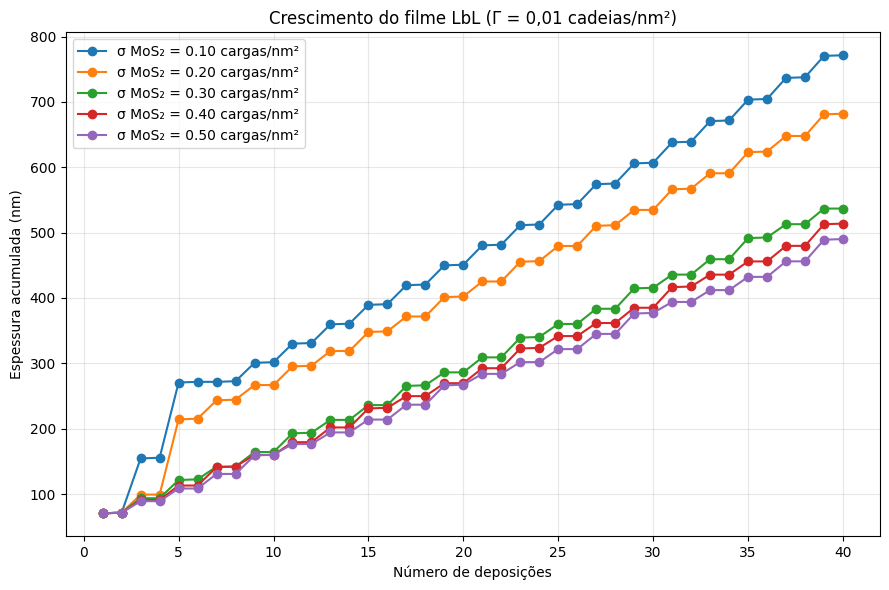

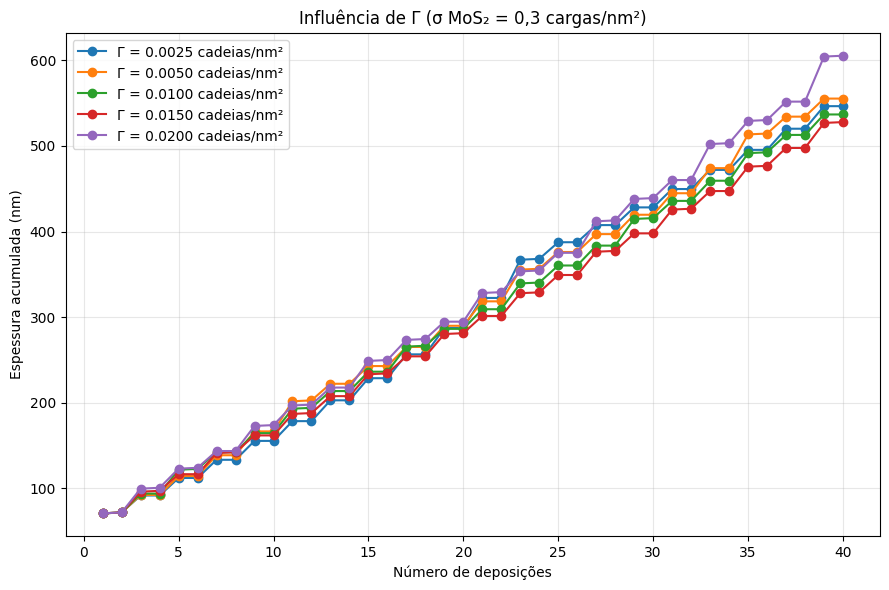

In [9]:
def curvas_espessura(Gammas, sigmas, titulo, legenda):
    plt.figure(figsize=(9, 6))
    for G, s in zip(Gammas, sigmas):
        df = simular_lbl(N_TENTATIVAS, G, s, "original")
        plt.plot(df["Tentativa"], df["Espessura (nm)"].cumsum(), marker="o",
                 label=legenda(G, s))
    plt.xlabel("Número de deposições")
    plt.ylabel("Espessura acumulada (nm)")
    plt.title(titulo)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# Fig. 6: Gamma fixo, varia sigma_MoS2
curvas_espessura([0.01] * 5, SIGMA_MOS2_VALUES, "Crescimento do filme LbL (Γ = 0,01 cadeias/nm²)",
                 lambda G, s: f"σ MoS₂ = {s:.2f} cargas/nm²")

# Fig. 7: sigma_MoS2 fixo, varia Gamma
curvas_espessura(GAMMA_VALUES["original"], [0.3] * 5,
                 "Influência de Γ (σ MoS₂ = 0,3 cargas/nm²)",
                 lambda G, s: f"Γ = {G:.4f} cadeias/nm²")

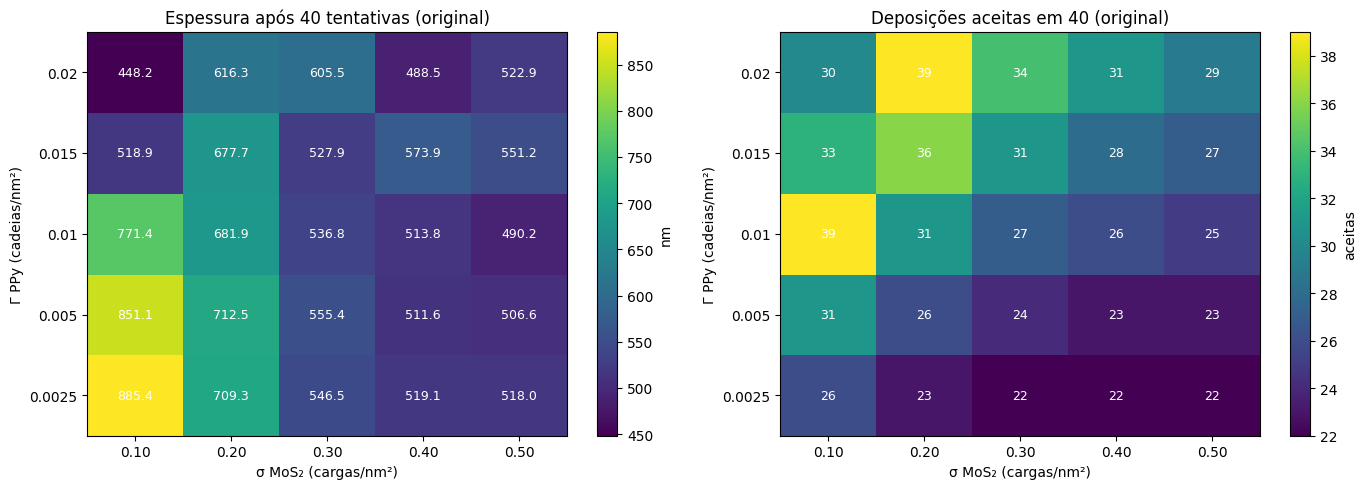

In [10]:
def heatmap(ax, dados, coluna, titulo, cbar_label, fmt):
    m = dados.pivot(index="Gamma", columns="sigma_mos2", values=coluna)
    im = ax.imshow(m.values, aspect="auto", origin="lower", interpolation="nearest")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, fmt.format(m.values[i, j]), ha="center", va="center", color="w", fontsize=9)
    ax.set_xticks(range(m.shape[1]), [f"{x:.2f}" for x in m.columns])
    ax.set_yticks(range(m.shape[0]), [f"{y:g}" for y in m.index])
    ax.set_xlabel("σ MoS₂ (cargas/nm²)")
    ax.set_ylabel("Γ PPy (cadeias/nm²)")
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label=cbar_label)


df_orig = varrer("original")

# Figs. 8 e 9 (modelo original)
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
heatmap(axs[0], df_orig, "espessura_total_nm", "Espessura após 40 tentativas (original)", "nm", "{:.1f}")
heatmap(axs[1], df_orig, "deposicoes_aceitas", "Deposições aceitas em 40 (original)", "aceitas", "{:.0f}")
plt.tight_layout()
plt.show()

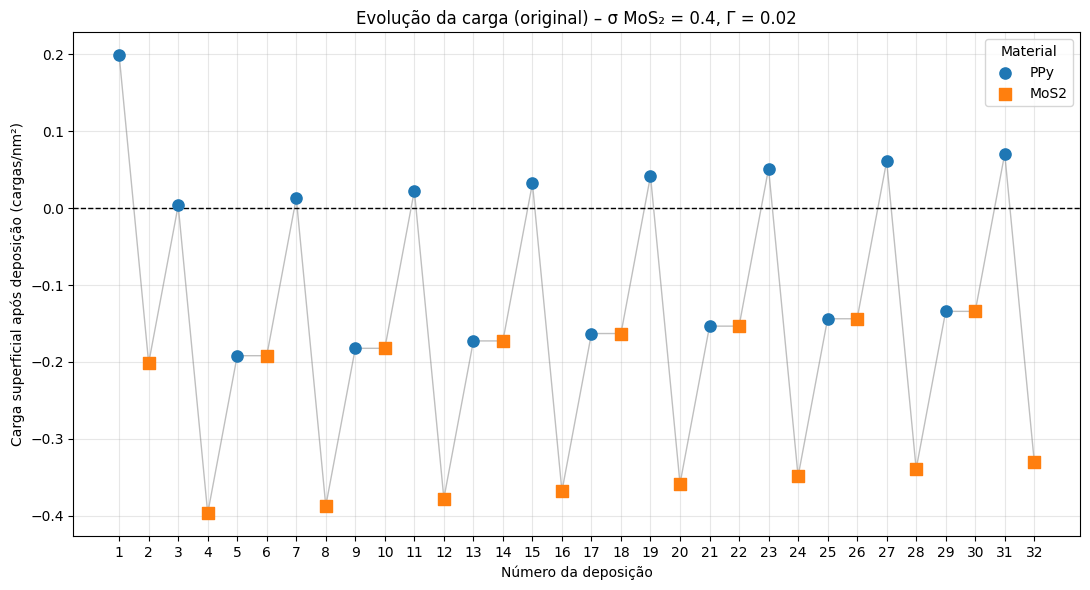

{'deposicoes_aceitas': 25, 'deposicoes_PPy': 16, 'deposicoes_MoS2': 9, 'espessura_total_nm': 395.92, 'carga_final': -0.3294}
kappa*delta (PPy): 25.3 a 101.1


In [11]:
def evolucao_carga(df, titulo):
    fig, ax = plt.subplots(figsize=(11, 6))
    for material, cor, mk in [("PPy", "tab:blue", "o"), ("MoS2", "tab:orange", "s")]:
        s = df[df["Material"] == material]
        ax.scatter(s["Tentativa"], s["Carga Após"], color=cor, marker=mk, s=65, label=material, zorder=3)
    ax.plot(df["Tentativa"], df["Carga Após"], color="gray", alpha=0.5, lw=1)
    ax.axhline(0, color="black", ls="--", lw=1)
    ax.set_xlabel("Número da deposição")
    ax.set_ylabel("Carga superficial após deposição (cargas/nm²)")
    ax.set_title(titulo)
    ax.set_xticks(df["Tentativa"])
    ax.grid(alpha=0.3)
    ax.legend(title="Material")
    plt.tight_layout()
    plt.show()


# Fig. 10: parâmetros escolhidos para o modelo original
G_ORIG, S_ORIG = 0.02, 0.4
df_fig10 = simular_lbl(32, G_ORIG, S_ORIG, "original")
evolucao_carga(df_fig10, f"Evolução da carga (original) – σ MoS₂ = {S_ORIG}, Γ = {G_ORIG}")
print(resumo(df_fig10))
print(f"kappa*delta (PPy): {df_fig10['kappa*delta'].min():.1f} a {df_fig10['kappa*delta'].max():.1f}")

## 7. Resultados — modelo acoplado

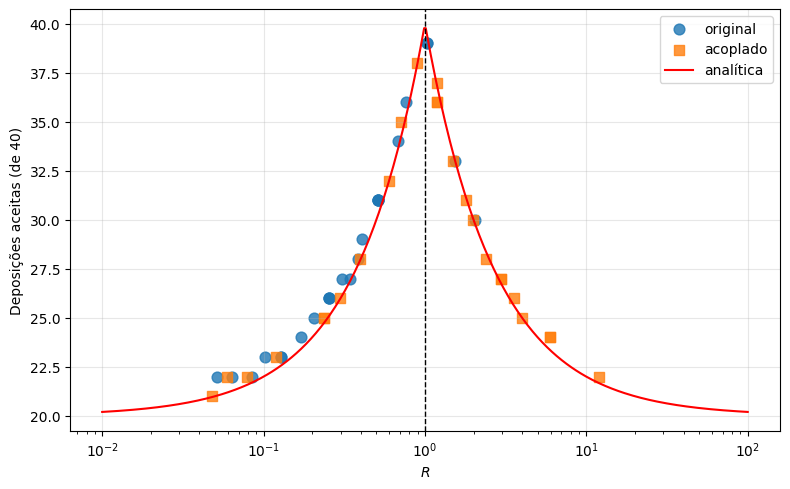

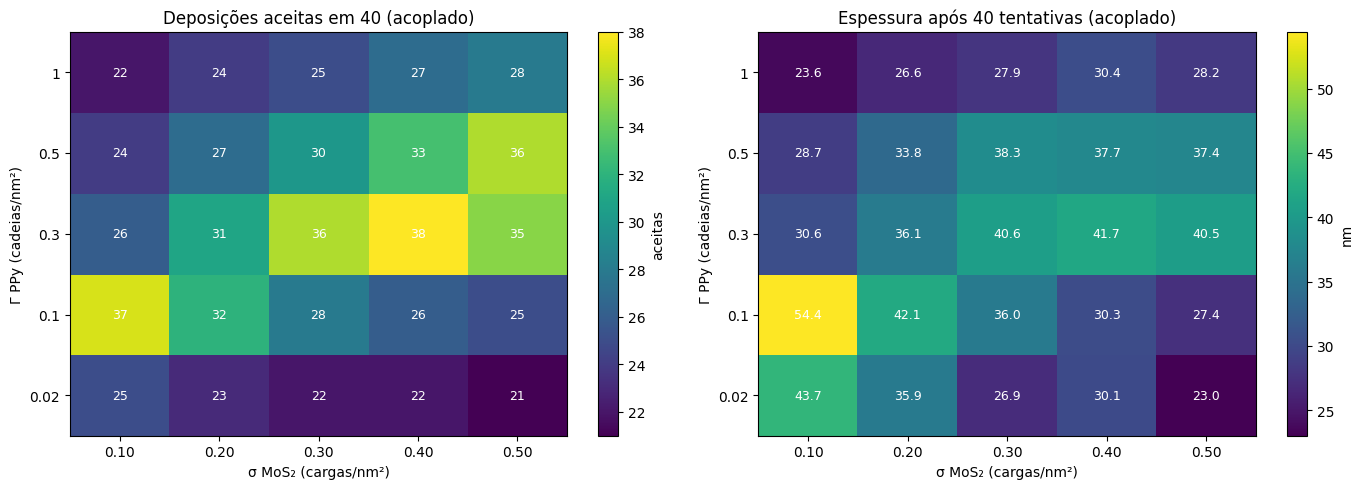

Espessura total (acoplado): 23.0 a 54.4 nm
Razão de cargas por cadeia (original/acoplado) = 8.60


In [12]:
df_acop = varrer("acoplado")
df_comp = pd.concat([df_orig, df_acop], ignore_index=True)

# Fig. 11: deposições aceitas x R, com a expressão analítica (eq. 56)
R = np.logspace(-2, 2, 400)
fig, ax = plt.subplots(figsize=(8, 5))
for modelo, mk in [("original", "o"), ("acoplado", "s")]:
    d = df_comp[df_comp["modelo"] == modelo]
    ax.scatter(d["R"], d["deposicoes_aceitas"], marker=mk, s=60, label=modelo, alpha=0.8)
ax.plot(R, N_TENTATIVAS / 2 * (1 + np.minimum(R, 1 / R)), "r-", label="analítica")
ax.axvline(1, ls="--", c="k", lw=1)
ax.set_xscale("log")
ax.set_xlabel(r"$R$")
ax.set_ylabel(f"Deposições aceitas (de {N_TENTATIVAS})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Figs. 12 e 13: mapas do modelo acoplado
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
heatmap(axs[0], df_acop, "deposicoes_aceitas", "Deposições aceitas em 40 (acoplado)", "aceitas", "{:.0f}")
heatmap(axs[1], df_acop, "espessura_total_nm", "Espessura após 40 tentativas (acoplado)", "nm", "{:.1f}")
plt.tight_layout()
plt.show()

print(f"Espessura total (acoplado): {df_acop['espessura_total_nm'].min():.1f} a "
      f"{df_acop['espessura_total_nm'].max():.1f} nm")
print(f"Razão de cargas por cadeia (original/acoplado) = {PARAMS['N'] * PARAMS['f'] / PONTE['q']:.2f}")

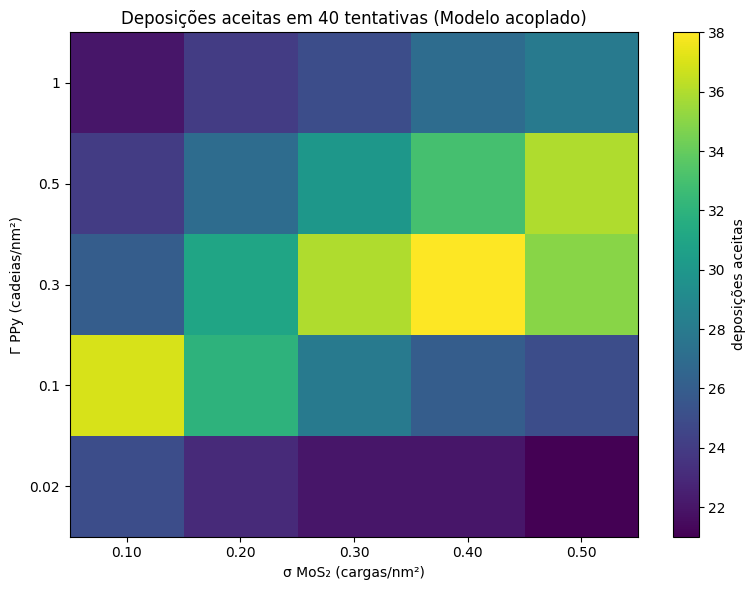

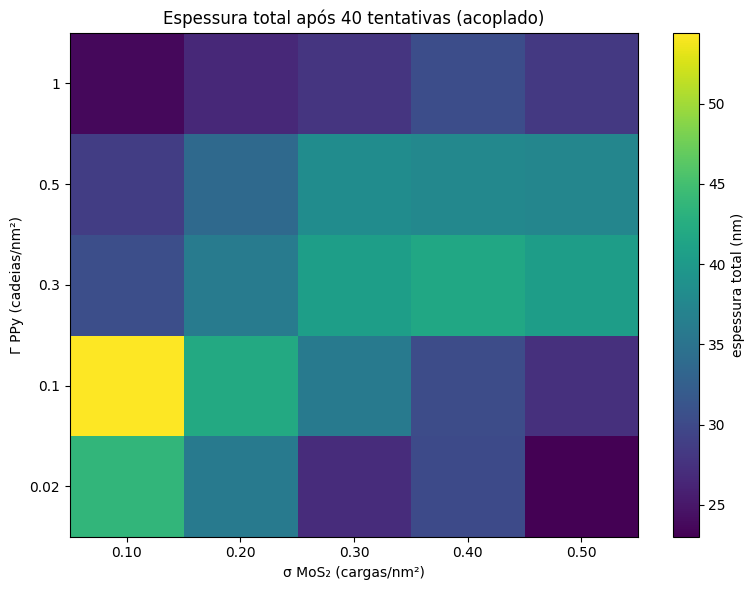

In [13]:
def heatmap_simples(dados, coluna, titulo, cbar_label):
    m = dados.pivot(index="Gamma", columns="sigma_mos2", values=coluna)
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(m.values, aspect="auto", origin="lower", interpolation="nearest")
    ax.set_xticks(range(m.shape[1]), [f"{x:.2f}" for x in m.columns])
    ax.set_yticks(range(m.shape[0]), [f"{y:g}" for y in m.index])
    ax.set_xlabel("σ MoS₂ (cargas/nm²)")
    ax.set_ylabel("Γ PPy (cadeias/nm²)")
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label=cbar_label)
    plt.tight_layout()
    plt.show()


heatmap_simples(df_acop, "deposicoes_aceitas",
                f"Deposições aceitas em {N_TENTATIVAS} tentativas (Modelo acoplado)", "deposições aceitas")
heatmap_simples(df_acop, "espessura_total_nm",
                f"Espessura total após {N_TENTATIVAS} tentativas (acoplado)", "espessura total (nm)")

min(R, 1/R) para 32 deposições = 0.60
 Gamma  sigma_mos2        R  deposicoes_aceitas  deposicoes_PPy  deposicoes_MoS2  espessura_total_nm
   0.1         0.2 0.595493                  32              20               12               42.12
   0.5         0.4 1.488732                  33              13               20               37.71
   0.3         0.2 1.786478                  31              11               20               36.09
   0.5         0.3 1.984976                  30              10               20               38.31
   0.3         0.5 0.714591                  35              20               15               40.48


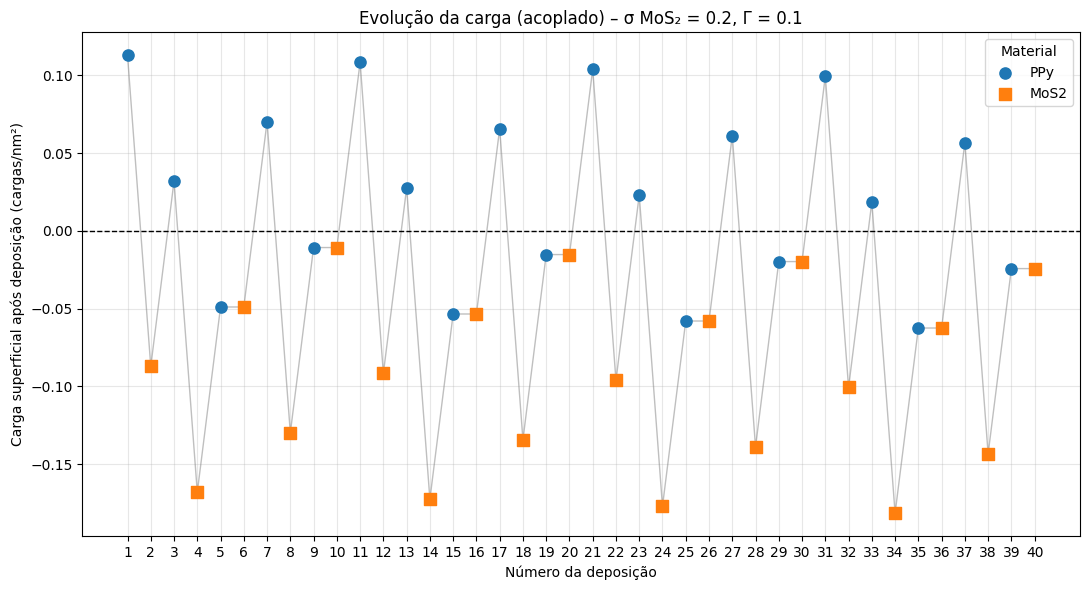

{'deposicoes_aceitas': 32, 'deposicoes_PPy': 20, 'deposicoes_MoS2': 12, 'espessura_total_nm': 42.12, 'carga_final': -0.0243} | R = 0.595


In [14]:
# Escolha dos parâmetros: 32 deposições aceitas -> min(R, 1/R) = 32/20 - 1 = 0,6
alvo = 32
m_alvo = alvo / (N_TENTATIVAS / 2) - 1
print(f"min(R, 1/R) para {alvo} deposições = {m_alvo:.2f}")
print((df_acop.assign(dist=(df_acop["deposicoes_aceitas"] - alvo).abs())
              .sort_values(["dist", "espessura_total_nm"], ascending=[True, False])
              .head(5)[["Gamma", "sigma_mos2", "R", "deposicoes_aceitas",
                        "deposicoes_PPy", "deposicoes_MoS2", "espessura_total_nm"]])
      .to_string(index=False))

# Fig. 14: evolução da carga para o par escolhido
G_ACOP, S_ACOP = 0.1, 0.2
df_fig14 = simular_lbl(N_TENTATIVAS, G_ACOP, S_ACOP, "acoplado")
evolucao_carga(df_fig14, f"Evolução da carga (acoplado) – σ MoS₂ = {S_ACOP}, Γ = {G_ACOP}")
print(resumo(df_fig14), f"| R = {G_ACOP * PONTE['q'] / S_ACOP:.3f}")

χ = 0.500: patamar δ = 59.4 nm
χ = 1.098: patamar δ = 34.7 nm
χ = 1.535: patamar δ = 23.4 nm
χ = 2.000: patamar δ = 16.8 nm


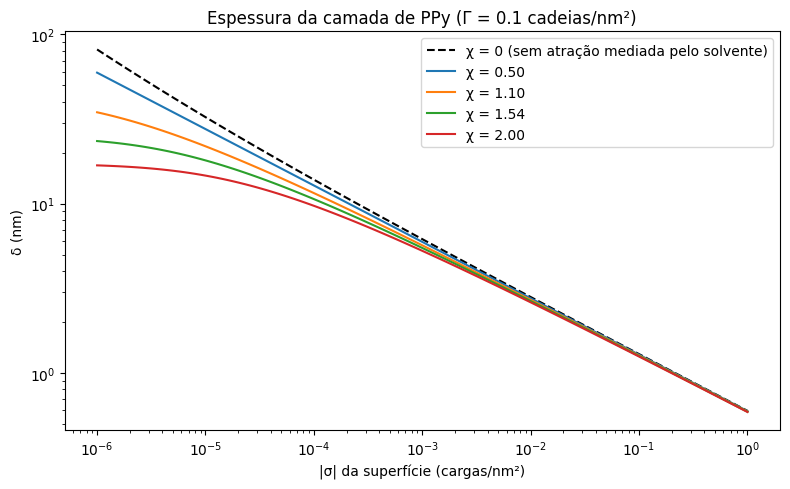

In [15]:
# ---------- Fig. 15: δ(σ) para diferentes χ ----------
sig = np.logspace(-6, 0, 120)
G_REF = 0.1
MOSTRAR_CONTORNO = False   # True: mostra o comprimento do oligômero médio (N_sol·a)

fig, ax = plt.subplots(figsize=(8, 5))

# Referência: mesma minimização com χ = 0 (só volume excluído, sem atração mediada pelo solvente)
d0 = [delta_campo_medio(s, G_REF, PONTE["N_sol"], F_PPY, 0.0, delta_max=1e3) for s in sig]
ax.plot(sig, d0, "k--", label="χ = 0 (sem atração mediada pelo solvente)")

for chi in [0.5, chi_hansen("acetonitrila"), CHI_PPY, 2.0]:
    dd = [delta_campo_medio(s, G_REF, PONTE["N_sol"], F_PPY, chi, delta_max=1e3) for s in sig]
    ax.plot(sig, dd, label=f"χ = {chi:.2f}")
    print(f"χ = {chi:.3f}: patamar δ = {max(dd):.1f} nm")

if MOSTRAR_CONTORNO:
    ax.axhline(PONTE["N_sol"] * A_UNIDADE_NM, color="gray", ls=":", label="contorno N_sol·a")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("|σ| da superfície (cargas/nm²)")
ax.set_ylabel("δ (nm)")
ax.set_title(f"Espessura da camada de PPy (Γ = {G_REF} cadeias/nm²)")
ax.legend()
plt.tight_layout()
plt.show()